# Training for with currents and d2c with the new model

The goal of this file is to train from  u ERA5,v ERA5, h piomas, u current, v current, d2cwind, d2cwind bound using the model which has both the angle and the norms as outputs

## Notes

SSh loses Removed 15760 rows (4.8%)
res loses none


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pickle

from tqdm.auto import tqdm
from time import strftime

from AIce.functions import torchRMSE,trainloader,redim,getRMSE,testloader
from  AIce.models import NNforNormsandAngles


In [10]:
filename='../data/TrainsetD2C.csv'
bs=256
inputlist=['u_ERA5','v_ERA5','h_piomas','res_uw','res_vw''d2cwind']
target='norm_and_angle'

datapd,dataset,dataloader,means,stds,maxes,labels=trainloader(filename, bs, inputlist, target, log1p=True, static_threshold=1e-3, 
                log1pwind=False, shuffle=True, dotcross=False, no_static=True,
                model_norm_angle=True
                )
print(means,stds)

static cases removed for training
allright angles
Buoynorm normalized by log1p
Building the target in form [norm,cos,sin] 
Wind components (u/v_ERA5) normalized by z-score
Residual-Currents loaded as components, normalized by z-score
{'u_ERA5': np.float64(-0.10887627996143148), 'v_ERA5': np.float64(0.36517261613512153), 'ssh_uw': np.float64(-0.009153500520192823), 'ssh_vw': np.float64(0.00963311292110588)} {'u_ERA5': 4.311998213364731, 'v_ERA5': 4.122416522925588, 'ssh_uw': 0.01858002639255804, 'ssh_vw': 0.021239381955381893}


In [ ]:
# Training loop for base inputs

device = torch.device(torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else 'cpu')

# Hyperparameters
lr=1e-3
n_epoch=200
print('Total Epoch: ', n_epoch)
print('Learning Rate: ', lr)
print(labels)


# saving name
print('DID YOU CHECK FOR THE RIGHT INPUT_TYPE')
input_type='_D2C_and_res_currents'
print(input_type, "<- is that what we want?")

saving_name=f'Norms_and_Angles_Inputs_{input_type}_{n_epoch}E_{lr}lr_{strftime("%d-%Hh_%Mm_%Ss")}'
month='3.November'

mlp256=NNforNormsandAngles(len(labels[1])).to(device) # Model
optimizer = optim.Adam(mlp256.parameters(),lr=lr) # optimizers


# Setting up losses for plotting 
losses={
    'total':{},
    'norm':{},
    'cos':{},
    'sin':{}
    } 
epoch_loss={
    'total':[],
    'norm':[],
    'cos':[],
    'sin':[],
    } 
avg_losses={
    'total':{},
    'norm':{},
    'cos':{},
    'sin':{}
    } 


# Setting up the overaching progress bar
epoch_bar = tqdm(range(n_epoch), 
                 desc='Training',            # NEW (outer bar)
                 position=0, 
                 unit='epoch')

for epoch in (epoch_bar):
    # Using the bar print out so no print('Starting Epoch ',epoch)
    
    # resetting loss trackers
    curpercent=0
    epoch_loss={
        'total':[],
        'norm':[],
        'cos':[],
        'sin':[],
        } 
    batch_bar = tqdm(dataloader, 
                     desc=f'Epoch {epoch+1}/{n_epoch}',   # NEW (inner bar)
                     position=1, 
                     leave=False, 
                     unit='batch')
    
    for i,data in enumerate(batch_bar): # using bars

        # get the inputs and the target
        truth,inputs= data[0].to(device),data[1].to(device)
        # truth is tensor shape [256, 3]
        # inputs is tensor shape [256, n_inputs]

        target_norm=truth[:,0] # Tensor shape (N,) 
        target_cos=truth[:,1]  # Tensor shape (N,)
        target_sin=truth[:,2]  # Tensor shape (N,)

        # zero the gradients,
        optimizer.zero_grad()

        # Forward,
        pred_norm,pred_cos,pred_sin=mlp256(inputs) # Tensor shape (N,), Tensor shape (N,), Tensor shape (N,) 


        normloss = torchRMSE(target=target_norm, outputs=pred_norm)
        cosloss = torchRMSE(target=target_cos, outputs=pred_cos)
        sinloss = torchRMSE(target=target_sin, outputs=pred_sin)
        loss= normloss+cosloss+sinloss

        # Backward
        loss.backward()

        # Optimize
        optimizer.step()

        # Saving Losses
        epoch_loss['total'].append(loss.item())
        epoch_loss['norm'].append(normloss.item())
        epoch_loss['cos'].append(cosloss.item())
        epoch_loss['sin'].append(sinloss.item())

        # NEW: running average of each loss over the batches seen so far this epoch
        batch_bar.set_postfix({k: f'{np.mean(v):.4f}' for k, v in epoch_loss.items()})
    batch_bar.close()


    losses['total'][epoch]=epoch_loss['total']
    losses['norm'][epoch]=epoch_loss['norm']
    losses['cos'][epoch]=epoch_loss['cos']
    losses['sin'][epoch]=epoch_loss['sin']

    avg_losses['total'][epoch]=np.average(epoch_loss['total'])
    avg_losses['norm'][epoch]=np.average(epoch_loss['norm'])
    avg_losses['cos'][epoch]=np.average(epoch_loss['cos'])
    avg_losses['sin'][epoch]=np.average(epoch_loss['sin'])

    # NEW: outer bar shows the average losses of the epoch that just finished
    epoch_bar.set_postfix({k: f'{v[epoch]:.4f}' for k, v in avg_losses.items()})
    # NEW (optional): permanent per-epoch record that doesn't break the bars
    epoch_bar.write(f'Epoch {epoch+1}: ' + ' | '.join(f'{k}={v[epoch]:.4f}' for k, v in avg_losses.items()))

# Making a loss plot
fig,ax = plt.subplots(

)

per_epoch_len=len(losses['total'][0])
max_plot=losses['total'][0][0]

x_line= np.arange(0,n_epoch)*per_epoch_len
x_avg=x_line+(per_epoch_len//2)
ax.plot(x_avg, avg_losses['total'].values(),'ko', label='Total Epoch-Average Loss ')
ax.plot(x_avg, avg_losses['norm'].values(),'ro' ,label='Norm Epoch-Average Loss')
ax.plot(x_avg, avg_losses['cos'].values(),'bo' ,label='Cos Epoch-Average Loss')
ax.plot(x_avg, avg_losses['sin'].values(),'go' ,label='Sin Epoch-Average Loss')

x_per_epoch=np.arange(0,per_epoch_len)
for i in range(n_epoch):
    xepoch=x_per_epoch+(i*per_epoch_len)
    ax.plot(xepoch,losses['total'][i],'k-', alpha=.3)
    ax.plot(xepoch,losses['norm'][i],'r-', alpha=.3)
    ax.plot(xepoch,losses['cos'][i],'b-', alpha=.3)
    ax.plot(xepoch,losses['sin'][i],'g-', alpha=.3)

ax.vlines(x_line,ymin=0,ymax = max_plot, linestyles= 'dashed', colors='cornflowerblue',alpha=.5, label='Epoch Starts')

ax.legend()

ax.set_ylim([0,max_plot])

ax.set_ylabel('Loss, non-dimensional')

ax.set_xlim([-5, n_epoch*per_epoch_len])
ax.set_xlabel('Epoch')

plt.savefig(f'.//outputs//training//loss_for_{saving_name}.png')
plt.show()


# Saving the model and it's info
torch.save(mlp256.state_dict(), f'.//weights//{saving_name}.pt')

with open(f'.//weights//{saving_name}.txt','w') as f:
    f.write(f'Model: NNforNormsandAngles (on gpu)\n')
    f.write(f'Weights: {saving_name}.pt\n')
    f.write(f'Associated inputs: {inputlist}\n')

# Store Losses (serialize)
with open(f'.//outputs//training//loss_{input_type}_{strftime("%d-%Hh_%Mm_%Ss")}.pickle', 'wb') as handle:
    pickle.dump(losses, handle, protocol=pickle.HIGHEST_PROTOCOL)

Total Epoch:  200
Learning Rate:  0.001
[Index(['buoynorm', 'cos_angle', 'sin_angle'], dtype='object'), Index(['u_ERA5', 'v_ERA5', 'h_piomas'], dtype='object')]
DID YOU CHECK FOR THE RIGHT INPUT_TYPE
_D2C_and_res_currents <- is that what we want?


Training:   0%|          | 0/200 [00:00<?, ?epoch/s]

Epoch 1/200:   0%|          | 0/1289 [00:00<?, ?batch/s]

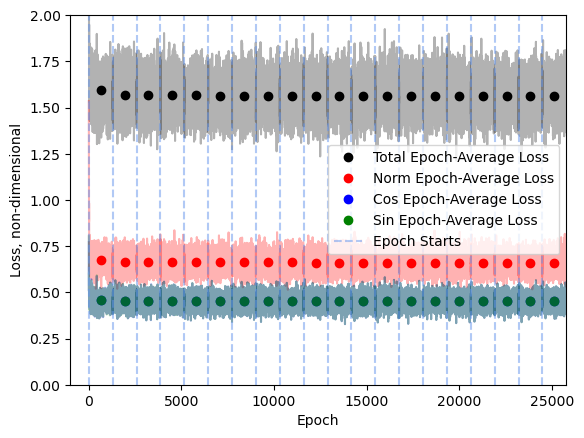

In [8]:
# Making a loss plot
fig,ax = plt.subplots(

)

per_epoch_len=len(losses['total'][0])
max_plot=losses['total'][0][0]

x_line= np.arange(0,n_epoch)*per_epoch_len
x_avg=x_line+(per_epoch_len//2)
ax.plot(x_avg, avg_losses['total'].values(),'ko', label='Total Epoch-Average Loss ')
ax.plot(x_avg, avg_losses['norm'].values(),'ro' ,label='Norm Epoch-Average Loss')
ax.plot(x_avg, avg_losses['cos'].values(),'bo' ,label='Cos Epoch-Average Loss')
ax.plot(x_avg, avg_losses['sin'].values(),'go' ,label='Sin Epoch-Average Loss')

x_per_epoch=np.arange(0,per_epoch_len)
for i in range(n_epoch):
    xepoch=x_per_epoch+(i*per_epoch_len)
    ax.plot(xepoch,losses['total'][i],'k-', alpha=.3)
    ax.plot(xepoch,losses['norm'][i],'r-', alpha=.3)
    ax.plot(xepoch,losses['cos'][i],'b-', alpha=.3)
    ax.plot(xepoch,losses['sin'][i],'g-', alpha=.3)

ax.vlines(x_line,ymin=0,ymax = max_plot, linestyles= 'dashed', colors='cornflowerblue',alpha=.5, label='Epoch Starts')

ax.legend()

ax.set_ylim([0,2])
# ax.set_yscale('log')
ax.set_ylabel('Loss, non-dimensional')

ax.set_xlim([-1000, n_epoch*per_epoch_len])
ax.set_xlabel('Epoch')

plt.savefig(f'.//outputs//training//loss_for_{saving_name}.png')
plt.show()


# some preanalysis of currents

c:\Users\testd\miniconda3\envs\mcgill\Lib\site-packages\matplotlib\axes\_axes.py:7104: RuntimeWarning: All-NaN slice encountered
  xmin = min(xmin, np.nanmin(xi))
c:\Users\testd\miniconda3\envs\mcgill\Lib\site-packages\matplotlib\axes\_axes.py:7105: RuntimeWarning: All-NaN slice encountered
  xmax = max(xmax, np.nanmax(xi))


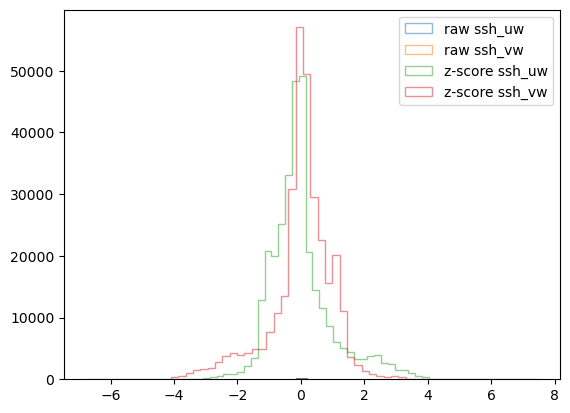

In [12]:
import xarray as xr
currents=  xr.open_dataset('../data/current/ssh_currents.nc')
fig,ax =plt.subplots()
ax.hist(currents['ssh_uw'],50, histtype='step', label='raw ssh_uw', alpha=.5)
ax.hist(currents['ssh_vw'],50, histtype='step', label= 'raw ssh_vw', alpha=.5)
ax.hist(datapd['ssh_uw'],50,histtype='step', label='z-score ssh_uw', alpha=.5)
ax.hist(datapd['ssh_vw'],50,histtype='step', label= 'z-score ssh_vw', alpha=.5)

ax.legend()